In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/esathyaprakash/electrical-fault-detection-and-classification/detect_dataset.csv
/kaggle/input/datasets/esathyaprakash/electrical-fault-detection-and-classification/classData.csv


In [3]:
# Load the datasets

detect_path = "/kaggle/input/datasets/esathyaprakash/electrical-fault-detection-and-classification/detect_dataset.csv"
class_path = "/kaggle/input/datasets/esathyaprakash/electrical-fault-detection-and-classification/classData.csv"

detect_df = pd.read_csv(detect_path)
class_df = pd.read_csv(class_path)

print("Detection Dataset Shape:", detect_df.shape)
print("Classification Dataset Shape:", class_df.shape)

print("\nDetection Dataset:")
display(detect_df.head())

print("\nClassification Dataset:")
display(class_df.head())

Detection Dataset Shape: (12001, 9)
Classification Dataset Shape: (7861, 10)

Detection Dataset:


,Output (S),Ia,Ib,Ic,Va,Vb,Vc,Unnamed: 7,Unnamed: 8
0,0,-170.472196,9.219613,161.252583,0.054490,-0.659921,0.605431,NaN,NaN
1,0,-122.235754,6.168667,116.067087,0.102000,-0.628612,0.526202,NaN,NaN
2,0,-90.161474,3.813632,86.347841,0.141026,-0.605277,0.464251,NaN,NaN
3,0,-79.904916,2.398803,77.506112,0.156272,-0.602235,0.445963,NaN,NaN
4,0,-63.885255,0.590667,63.294587,0.180451,-0.591501,0.411050,NaN,NaN



Classification Dataset:


,G,C,B,A,Ia,Ib,Ic,Va,Vb,Vc
0,1,0,0,1,-151.291812,-9.677452,85.800162,0.400750,-0.132935,-0.267815
1,1,0,0,1,-336.186183,-76.283262,18.328897,0.312732,-0.123633,-0.189099
2,1,0,0,1,-502.891583,-174.648023,-80.924663,0.265728,-0.114301,-0.151428
3,1,0,0,1,-593.941905,-217.703359,-124.891924,0.235511,-0.104940,-0.130570
4,1,0,0,1,-643.663617,-224.159427,-132.282815,0.209537,-0.095554,-0.113983


In [4]:
print("========== DETECTION DATASET ==========")

print("\nColumns:")
print(detect_df.columns.tolist())

print("\nData Types:")
print(detect_df.dtypes)

print("\n========== CLASSIFICATION DATASET ==========")

print("\nColumns:")
print(class_df.columns.tolist())

print("\nData Types:")
print(class_df.dtypes)

========== DETECTION DATASET ==========

Columns:
['Output (S)', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc', 'Unnamed: 7', 'Unnamed: 8']

Data Types:
Output (S)      int64
Ia            float64
Ib            float64
Ic            float64
Va            float64
Vb            float64
Vc            float64
Unnamed: 7    float64
Unnamed: 8    float64
dtype: object

========== CLASSIFICATION DATASET ==========

Columns:
['G', 'C', 'B', 'A', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

Data Types:
G       int64
C       int64
B       int64
A       int64
Ia    float64
Ib    float64
Ic    float64
Va    float64
Vb    float64
Vc    float64
dtype: object


In [5]:
print("========== DETECTION DATASET INFO ==========")
detect_df.info()

print("\n========== CLASSIFICATION DATASET INFO ==========")
class_df.info()

========== DETECTION DATASET INFO ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12001 entries, 0 to 12000
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Output (S)  12001 non-null  int64  
 1   Ia          12001 non-null  float64
 2   Ib          12001 non-null  float64
 3   Ic          12001 non-null  float64
 4   Va          12001 non-null  float64
 5   Vb          12001 non-null  float64
 6   Vc          12001 non-null  float64
 7   Unnamed: 7  0 non-null      float64
 8   Unnamed: 8  0 non-null      float64
dtypes: float64(8), int64(1)
memory usage: 843.9 KB

========== CLASSIFICATION DATASET INFO ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7861 entries, 0 to 7860
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   G       7861 non-null   int64  
 1   C       7861 non-null   int64  
 2   B       7861 non-null   int64  
 

In [6]:
print("\nDetection Dataset Description:")
display(detect_df.describe(include='all'))

print("\nClassification Dataset Description:")
display(class_df.describe(include='all'))


Detection Dataset Description:


,Output (S),Ia,Ib,Ic,Va,Vb,Vc,Unnamed: 7,Unnamed: 8
count,12001.000000,12001.000000,12001.000000,12001.000000,12001.000000,12001.000000,12001.000000,0.0,0.0
mean,0.457962,6.709369,-26.557793,22.353043,0.010517,-0.015498,0.004980,NaN,NaN
std,0.498250,377.158470,357.458613,302.052809,0.346221,0.357644,0.349272,NaN,NaN
min,0.000000,-883.542316,-900.526951,-883.357762,-0.620748,-0.659921,-0.612709,NaN,NaN
25%,0.000000,-64.348986,-51.421937,-54.562257,-0.237610,-0.313721,-0.278951,NaN,NaN
50%,0.000000,-3.239788,4.711283,-0.399419,0.002465,-0.007192,0.008381,NaN,NaN
75%,1.000000,53.823453,69.637787,45.274542,0.285078,0.248681,0.289681,NaN,NaN
max,1.000000,885.738571,889.868884,901.274261,0.609864,0.627875,0.608243,NaN,NaN



Classification Dataset Description:


,G,C,B,A,Ia,Ib,Ic,Va,Vb,Vc
count,7861.000000,7861.000000,7861.000000,7861.000000,7861.000000,7861.000000,7861.000000,7861.000000,7861.000000,7861.000000
mean,0.432006,0.411271,0.555527,0.571429,13.721194,-44.845268,34.392394,-0.007667,0.001152,0.006515
std,0.495387,0.492095,0.496939,0.494903,464.741671,439.269195,371.107412,0.289150,0.313437,0.307897
min,0.000000,0.000000,0.000000,0.000000,-883.542316,-900.526951,-883.357762,-0.620748,-0.608016,-0.612709
25%,0.000000,0.000000,0.000000,0.000000,-119.802518,-271.845947,-61.034219,-0.130287,-0.159507,-0.215977
50%,0.000000,0.000000,1.000000,1.000000,2.042805,5.513317,-4.326711,-0.005290,0.001620,0.009281
75%,1.000000,1.000000,1.000000,1.000000,227.246377,91.194282,49.115141,0.111627,0.153507,0.239973
max,1.000000,1.000000,1.000000,1.000000,885.738571,889.868884,901.274261,0.595342,0.627875,0.600179


In [7]:
print("Missing Values - Detection Dataset")
print(detect_df.isnull().sum())

print("\nMissing Values - Classification Dataset")
print(class_df.isnull().sum())

Missing Values - Detection Dataset
Output (S)        0
Ia                0
Ib                0
Ic                0
Va                0
Vb                0
Vc                0
Unnamed: 7    12001
Unnamed: 8    12001
dtype: int64

Missing Values - Classification Dataset
G     0
C     0
B     0
A     0
Ia    0
Ib    0
Ic    0
Va    0
Vb    0
Vc    0
dtype: int64


In [9]:
print("Duplicate rows in Detection Dataset:",
      detect_df.duplicated().sum())

print("Duplicate rows in Classification Dataset:",
      class_df.duplicated().sum())

Duplicate rows in Detection Dataset: 0
Duplicate rows in Classification Dataset: 0


In [10]:
# Check the distribution of the detection target

print("Output (S) value counts:")
print(detect_df['Output (S)'].value_counts())

print("\nOutput (S) percentages:")
print(detect_df['Output (S)'].value_counts(normalize=True) * 100)

Output (S) value counts:
Output (S)
0    6505
1    5496
Name: count, dtype: int64

Output (S) percentages:
Output (S)
0    54.203816
1    45.796184
Name: proportion, dtype: float64


In [11]:
print("Unnamed: 7 unique values:")
print(detect_df['Unnamed: 7'].unique()[:20])

print("\nUnnamed: 8 unique values:")
print(detect_df['Unnamed: 8'].unique()[:20])

print("\nNumber of missing values:")
print(detect_df[['Unnamed: 7', 'Unnamed: 8']].isnull().sum())

Unnamed: 7 unique values:
[nan]

Unnamed: 8 unique values:
[nan]

Number of missing values:
Unnamed: 7    12001
Unnamed: 8    12001
dtype: int64


In [12]:
measurement_columns = [
    'Ia', 'Ib', 'Ic',
    'Va', 'Vb', 'Vc'
]

display(detect_df[measurement_columns].describe())

,Ia,Ib,Ic,Va,Vb,Vc
count,12001.000000,12001.000000,12001.000000,12001.000000,12001.000000,12001.000000
mean,6.709369,-26.557793,22.353043,0.010517,-0.015498,0.004980
std,377.158470,357.458613,302.052809,0.346221,0.357644,0.349272
min,-883.542316,-900.526951,-883.357762,-0.620748,-0.659921,-0.612709
25%,-64.348986,-51.421937,-54.562257,-0.237610,-0.313721,-0.278951
50%,-3.239788,4.711283,-0.399419,0.002465,-0.007192,0.008381
75%,53.823453,69.637787,45.274542,0.285078,0.248681,0.289681
max,885.738571,889.868884,901.274261,0.609864,0.627875,0.608243


In [13]:
# Correlation of numerical columns with the target

correlation = detect_df.corr(numeric_only=True)['Output (S)'].sort_values(
    ascending=False
)

print("Correlation with Output (S):")
display(correlation)

Correlation with Output (S):


Output (S)    1.000000
Ic            0.120044
Ia            0.039408
Vc            0.022570
Vb            0.012206
Va           -0.035377
Ib           -0.134028
Unnamed: 7         NaN
Unnamed: 8         NaN
Name: Output (S), dtype: float64

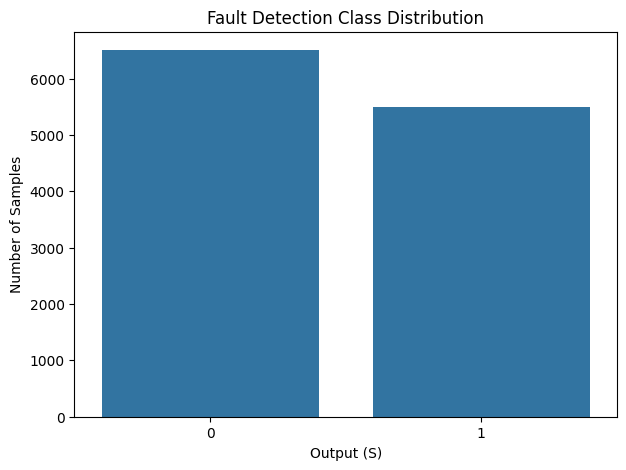

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=detect_df,
    x='Output (S)'
)

plt.title('Fault Detection Class Distribution')
plt.xlabel('Output (S)')
plt.ylabel('Number of Samples')
plt.show()

In [15]:
# Create a clean copy of the detection dataset

detection_clean = detect_df.copy()

# Remove unnecessary unnamed columns
detection_clean = detection_clean.drop(
    columns=['Unnamed: 7', 'Unnamed: 8'],
    errors='ignore'
)

print("Clean dataset shape:", detection_clean.shape)

print("\nClean columns:")
print(detection_clean.columns.tolist())

display(detection_clean.head())

Clean dataset shape: (12001, 7)

Clean columns:
['Output (S)', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']


,Output (S),Ia,Ib,Ic,Va,Vb,Vc
0,0,-170.472196,9.219613,161.252583,0.054490,-0.659921,0.605431
1,0,-122.235754,6.168667,116.067087,0.102000,-0.628612,0.526202
2,0,-90.161474,3.813632,86.347841,0.141026,-0.605277,0.464251
3,0,-79.904916,2.398803,77.506112,0.156272,-0.602235,0.445963
4,0,-63.885255,0.590667,63.294587,0.180451,-0.591501,0.411050


In [16]:
# Features
X = detection_clean[
    ['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']
]

# Target
y = detection_clean['Output (S)']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.unique())

Feature shape: (12001, 6)
Target shape: (12001,)

Features:
['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

Target values:
[0 1]


In [17]:
print("Missing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Missing values in X:
Ia    0
Ib    0
Ic    0
Va    0
Vb    0
Vc    0
dtype: int64

Missing values in y:
0


In [18]:
print("Unique target values:")
print(sorted(y.unique()))

print("\nTarget data type:")
print(y.dtype)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Unique target values:
[np.int64(0), np.int64(1)]

Target data type:
int64

Target distribution:
Output (S)
0    6505
1    5496
Name: count, dtype: int64


In [19]:
target_counts = y.value_counts().sort_index()

print("Target distribution:")
display(target_counts)

print("\nTarget percentage:")
display((target_counts / len(y) * 100).round(2))

Target distribution:


Output (S)
0    6505
1    5496
Name: count, dtype: int64


Target percentage:


Output (S)
0    54.2
1    45.8
Name: count, dtype: float64

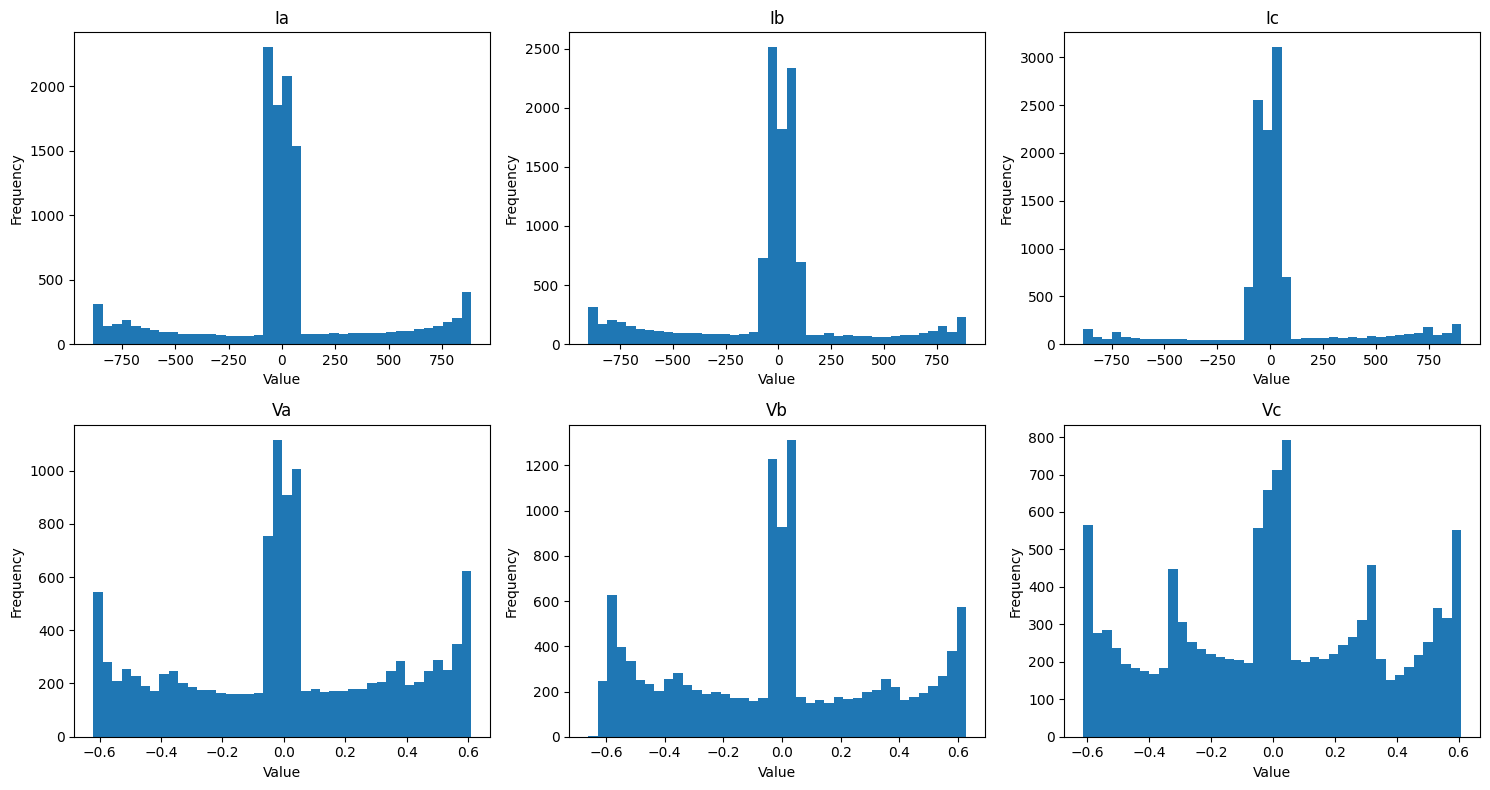

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

features = ['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

for ax, feature in zip(axes.flatten(), features):
    ax.hist(detection_clean[feature], bins=40)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [21]:
for feature in features:
    print(f"\n========== {feature} ==========")
    print(
        detection_clean.groupby('Output (S)')[feature]
        .agg(['mean', 'std', 'min', 'max'])
    )


========== Ia ==========
                 mean         std         min         max
Output (S)                                               
0           -6.951763   44.821487 -170.472196  104.097945
1           22.878521  554.781504 -883.542316  885.738571

========== Ib ==========
                 mean         std         min         max
Output (S)                                               
0           17.477828   47.800584 -106.276732  100.247141
1          -78.677828  520.885891 -900.526951  889.868884

========== Ic ==========
                 mean         std         min         max
Output (S)                                               
0          -10.974558   48.027380 -107.423073  161.252583
1           61.799193  440.045373 -883.357762  901.274261

========== Va ==========
                mean       std       min       max
Output (S)                                        
0           0.021775  0.432161 -0.620748  0.609864
1          -0.002807  0.200961 -0.508612  0.518

In [22]:
X = detection_clean[
    ['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']
].copy()

y = detection_clean['Output (S)'].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

X shape: (12001, 6)
y shape: (12001,)

X columns:
['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training samples: 9600
Testing samples : 2401

Training class distribution:
Output (S)
0    0.542083
1    0.457917
Name: proportion, dtype: float64

Testing class distribution:
Output (S)
0    0.541858
1    0.458142
Name: proportion, dtype: float64


In [24]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [25]:
y_pred = rf_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 99.33%


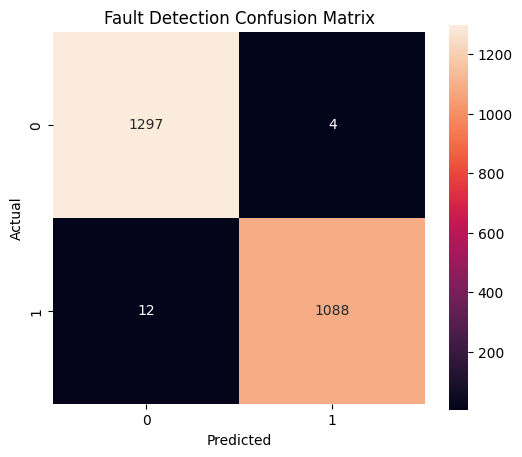

In [26]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    square=True
)

plt.title('Fault Detection Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [27]:
# Predictions on training data
y_train_pred = rf_model.predict(X_train)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy : {test_accuracy * 100:.2f}%")

Training Accuracy: 99.28%
Testing Accuracy : 99.33%


In [28]:
# Check duplicate feature combinations between train and test

train_features = set(map(tuple, X_train.values))
test_features = set(map(tuple, X_test.values))

overlap = train_features.intersection(test_features)

print("Unique feature combinations in training:", len(train_features))
print("Unique feature combinations in testing :", len(test_features))
print("Overlapping feature combinations        :", len(overlap))

Unique feature combinations in training: 9600
Unique feature combinations in testing : 2401
Overlapping feature combinations        : 0


In [29]:
print("Total samples:", len(X))

print(
    "Unique electrical measurement combinations:",
    X.drop_duplicates().shape[0]
)

print(
    "Repeated measurement combinations:",
    len(X) - X.drop_duplicates().shape[0]
)

Total samples: 12001
Unique electrical measurement combinations: 12001
Repeated measurement combinations: 0


In [30]:
feature_columns = ['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

label_consistency = (
    detection_clean
    .groupby(feature_columns)['Output (S)']
    .nunique()
)

print("Measurement combinations with multiple labels:",
      (label_consistency > 1).sum())

print("Measurement combinations with one label:",
      (label_consistency == 1).sum())

Measurement combinations with multiple labels: 0
Measurement combinations with one label: 12001


In [31]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)

print(f"Decision Tree Test Accuracy: {dt_accuracy * 100:.2f}%")

Decision Tree Test Accuracy: 99.21%


In [14]:
# ============================================
# QML SETUP: IMPORT REQUIRED LIBRARIES
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

print("Required libraries imported successfully!")

Required libraries imported successfully!


In [15]:
# ============================================
# QML CELL 1: LOAD CLASSIFICATION DATA
# ============================================

class_path = "/kaggle/input/datasets/esathyaprakash/electrical-fault-detection-and-classification/classData.csv"

classification_clean = pd.read_csv(class_path)

print("Classification dataset shape:")
print(classification_clean.shape)

print("\nColumns:")
print(classification_clean.columns.tolist())

display(classification_clean.head())

Classification dataset shape:
(7861, 10)

Columns:
['G', 'C', 'B', 'A', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']


,G,C,B,A,Ia,Ib,Ic,Va,Vb,Vc
0,1,0,0,1,-151.291812,-9.677452,85.800162,0.400750,-0.132935,-0.267815
1,1,0,0,1,-336.186183,-76.283262,18.328897,0.312732,-0.123633,-0.189099
2,1,0,0,1,-502.891583,-174.648023,-80.924663,0.265728,-0.114301,-0.151428
3,1,0,0,1,-593.941905,-217.703359,-124.891924,0.235511,-0.104940,-0.130570
4,1,0,0,1,-643.663617,-224.159427,-132.282815,0.209537,-0.095554,-0.113983


In [16]:
# ============================================
# QML CELL 2: CREATE FAULT TYPE
# ============================================

# Create a four-bit fault code from G, C, B, A
classification_clean['Fault_Code'] = (
    classification_clean['G'].astype(str) +
    classification_clean['C'].astype(str) +
    classification_clean['B'].astype(str) +
    classification_clean['A'].astype(str)
)

# Map fault codes to fault types
fault_mapping = {
    '0000': 'No Fault',
    '1001': 'LG Fault',
    '0110': 'LL Fault',
    '1011': 'LLG Fault',
    '0111': 'LLL Fault',
    '1111': 'LLLG Fault'
}

classification_clean['Fault_Type'] = (
    classification_clean['Fault_Code'].map(fault_mapping)
)

print("Fault types created successfully!")

display(
    classification_clean[
        ['G', 'C', 'B', 'A', 'Fault_Code', 'Fault_Type']
    ].head(10)
)

Fault types created successfully!


,G,C,B,A,Fault_Code,Fault_Type
0,1,0,0,1,1001,LG Fault
1,1,0,0,1,1001,LG Fault
2,1,0,0,1,1001,LG Fault
3,1,0,0,1,1001,LG Fault
4,1,0,0,1,1001,LG Fault
5,1,0,0,1,1001,LG Fault
6,1,0,0,1,1001,LG Fault
7,1,0,0,1,1001,LG Fault
8,1,0,0,1,1001,LG Fault
9,1,0,0,1,1001,LG Fault


In [17]:
# ============================================
# QML CELL 3: VERIFY FAULT TYPES
# ============================================

print("Fault Type Distribution:")
display(
    classification_clean['Fault_Type'].value_counts()
)

print("\nUnknown Fault Types:")
print(
    classification_clean['Fault_Type'].isna().sum()
)

Fault Type Distribution:


Fault_Type
No Fault      2365
LLG Fault     1134
LLLG Fault    1133
LG Fault      1129
LLL Fault     1096
LL Fault      1004
Name: count, dtype: int64


Unknown Fault Types:
0


In [18]:
# ============================================
# QML CELL 4: SELECT QML FEATURES
# ============================================

qml_features = [
    'Ia', 'Ib', 'Ic',
    'Va', 'Vb', 'Vc'
]

X_class = classification_clean[qml_features].copy()
y_class = classification_clean['Fault_Type'].copy()

print("QML Features:")
print(qml_features)

print("\nFeature shape:", X_class.shape)
print("Target shape:", y_class.shape)

QML Features:
['Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

Feature shape: (7861, 6)
Target shape: (7861,)


In [19]:
# ============================================
# QML CELL 5: LABEL ENCODING
# ============================================

label_encoder = LabelEncoder()

y_class_encoded = label_encoder.fit_transform(
    y_class
)

n_classes = len(label_encoder.classes_)

print("Number of fault classes:", n_classes)

print("\nFault class encoding:")

for i, label in enumerate(label_encoder.classes_):
    print(f"{i} -> {label}")

Number of fault classes: 6

Fault class encoding:
0 -> LG Fault
1 -> LL Fault
2 -> LLG Fault
3 -> LLL Fault
4 -> LLLG Fault
5 -> No Fault


In [20]:
# ============================================
# QML CELL 6: TRAIN / TEST SPLIT
# ============================================

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_class_encoded
)

print("QML training samples:", len(X_class_train))
print("QML testing samples :", len(X_class_test))

QML training samples: 6288
QML testing samples : 1573


In [21]:
# ============================================
# QML CELL 7: FEATURE SCALING
# ============================================

qml_scaler = StandardScaler()

# Fit only on training data
X_qml_train_scaled = qml_scaler.fit_transform(
    X_class_train
)

# Transform test data
X_qml_test_scaled = qml_scaler.transform(
    X_class_test
)

print("QML feature scaling completed.")
print("Training shape:", X_qml_train_scaled.shape)
print("Testing shape :", X_qml_test_scaled.shape)

QML feature scaling completed.
Training shape: (6288, 6)
Testing shape : (1573, 6)


In [22]:
# ============================================
# QML CELL 8: PCA
# 6 FEATURES → 4 FEATURES
# ============================================

pca = PCA(n_components=4)

# Fit PCA only on training data
X_qml_train_pca = pca.fit_transform(
    X_qml_train_scaled
)

# Transform test data
X_qml_test_pca = pca.transform(
    X_qml_test_scaled
)

print("PCA completed successfully.")

print("\nOriginal features:",
      X_qml_train_scaled.shape[1])

print("PCA features:",
      X_qml_train_pca.shape[1])

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal explained variance:",
    pca.explained_variance_ratio_.sum()
)

PCA completed successfully.

Original features: 6
PCA features: 4

Explained variance ratio:
[0.30807589 0.25702851 0.22569966 0.18138471]

Total explained variance: 0.9721887743503911


In [23]:
# ============================================
# QML CELL 9: CONVERT DATA TO PYTORCH
# ============================================

X_train_tensor = torch.tensor(
    X_qml_train_pca,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_class_train,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_qml_test_pca,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_class_test,
    dtype=torch.long
)

print("Training features:", X_train_tensor.shape)
print("Training labels  :", y_train_tensor.shape)

print("\nTesting features:", X_test_tensor.shape)
print("Testing labels  :", y_test_tensor.shape)

Training features: torch.Size([6288, 4])
Training labels  : torch.Size([6288])

Testing features: torch.Size([1573, 4])
Testing labels  : torch.Size([1573])


In [24]:
# ============================================
# QML CELL 10: MINI-BATCH DATA
# ============================================

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Mini-batch training prepared.")
print("Batch size:", 32)
print("Number of batches:", len(train_loader))

Mini-batch training prepared.
Batch size: 32
Number of batches: 197


In [26]:
# ============================================
# QML CELL 11
# ============================================
import pennylane as qml
import torch
import torch.nn as nn

# Number of qubits
n_qubits = 4

# Number of variational layers
n_layers = 4

# Quantum simulator
dev = qml.device("default.qubit", wires=n_qubits)

print("Quantum device created successfully.")
print("Number of qubits:", n_qubits)
print("Number of VQC layers:", n_layers)

Quantum device created successfully.
Number of qubits: 4
Number of VQC layers: 4


In [27]:
# ============================================
# QML CELL 12
# ===========================================
@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):

    # Encode the 4 PCA features into 4 qubits
    qml.AngleEmbedding(
        inputs,
        wires=range(n_qubits),
        rotation="Y"
    )

    # Variational quantum layers
    qml.StronglyEntanglingLayers(
        weights,
        wires=range(n_qubits)
    )

    # Measure X, Y and Z expectation values
    return (
        [qml.expval(qml.PauliX(i)) for i in range(n_qubits)] +
        [qml.expval(qml.PauliY(i)) for i in range(n_qubits)] +
        [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]
    )


weight_shapes = {
    "weights": (n_layers, n_qubits, 3)
}

print("VQC circuit created successfully.")
print("Qubits:", n_qubits)
print("Layers:", n_layers)
print("Quantum output features:", n_qubits * 3)

VQC circuit created successfully.
Qubits: 4
Layers: 4
Quantum output features: 12


In [29]:
# ============================================
# QML CELL 13
# ===========================================
# Take one sample from the QML training data
sample_input = X_train_tensor[0]

# Create random initial quantum weights
sample_weights = torch.randn(
    n_layers,
    n_qubits,
    3,
    dtype=torch.float32
)

# Run the quantum circuit
quantum_output = quantum_circuit(
    sample_input,
    sample_weights
)

# Convert the output list into a tensor
quantum_output = torch.stack(quantum_output)

print("Quantum circuit test successful.")
print("Input shape :", sample_input.shape)
print("Output shape:", quantum_output.shape)
print("\nQuantum output:")
print(quantum_output)

Quantum circuit test successful.
Input shape : torch.Size([4])
Output shape: torch.Size([12])

Quantum output:
tensor([ 0.2406,  0.0335,  0.1022, -0.1102, -0.2654, -0.0909, -0.1773,  0.6364,
         0.5367, -0.6136, -0.5446,  0.1965], dtype=torch.float64)


In [30]:
# ============================================
# QML CELL 14
# ===========================================
class HybridQuantumClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        # Quantum layer
        self.quantum_layer = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes
        )

        # Classical neural network
        self.classifier = nn.Sequential(
            nn.Linear(12, 24),
            nn.ReLU(),

            nn.Linear(24, 12),
            nn.ReLU(),

            nn.Linear(12, n_classes)
        )

    def forward(self, x):

        # Generate quantum features
        x = self.quantum_layer(x)

        # Convert to float32 for PyTorch
        x = x.float()

        # Classical classification
        x = self.classifier(x)

        return x


# Create the hybrid model
qml_model = HybridQuantumClassifier()

print("Hybrid Quantum-Classical model created successfully.")
print(qml_model)

Hybrid Quantum-Classical model created successfully.
HybridQuantumClassifier(
  (quantum_layer): <Quantum Torch Layer: func=quantum_circuit>
  (classifier): Sequential(
    (0): Linear(in_features=12, out_features=24, bias=True)
    (1): ReLU()
    (2): Linear(in_features=24, out_features=12, bias=True)
    (3): ReLU()
    (4): Linear(in_features=12, out_features=6, bias=True)
  )
)


In [31]:
# ============================================
# QML CELL 15
# ===========================================
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    qml_model.parameters(),
    lr=0.002
)

# Number of epochs
epochs = 40

training_losses = []
training_accuracies = []

print("Starting QML training...\n")

for epoch in range(epochs):

    qml_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch_X, batch_y in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = qml_model(batch_X)

        # Calculate loss
        loss = criterion(outputs, batch_y)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        # Track loss
        total_loss += loss.item()

        # Calculate training accuracy
        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == batch_y).sum().item()
        total += batch_y.size(0)

    epoch_loss = total_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    training_losses.append(epoch_loss)
    training_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1:02d}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

print("\nQML training completed successfully.")

Starting QML training...

Epoch [01/40] Loss: 1.3528 Accuracy: 44.69%
Epoch [02/40] Loss: 0.6995 Accuracy: 69.10%
Epoch [03/40] Loss: 0.5796 Accuracy: 73.49%
Epoch [04/40] Loss: 0.5128 Accuracy: 76.97%
Epoch [05/40] Loss: 0.4644 Accuracy: 79.02%
Epoch [06/40] Loss: 0.4307 Accuracy: 80.36%
Epoch [07/40] Loss: 0.4043 Accuracy: 80.76%
Epoch [08/40] Loss: 0.3884 Accuracy: 81.15%
Epoch [09/40] Loss: 0.3757 Accuracy: 81.70%
Epoch [10/40] Loss: 0.3609 Accuracy: 81.58%
Epoch [11/40] Loss: 0.3535 Accuracy: 81.87%
Epoch [12/40] Loss: 0.3444 Accuracy: 81.98%
Epoch [13/40] Loss: 0.3363 Accuracy: 82.36%
Epoch [14/40] Loss: 0.3305 Accuracy: 82.20%
Epoch [15/40] Loss: 0.3276 Accuracy: 82.55%
Epoch [16/40] Loss: 0.3248 Accuracy: 82.86%
Epoch [17/40] Loss: 0.3171 Accuracy: 82.67%
Epoch [18/40] Loss: 0.3134 Accuracy: 82.98%
Epoch [19/40] Loss: 0.3112 Accuracy: 83.25%
Epoch [20/40] Loss: 0.3061 Accuracy: 83.29%
Epoch [21/40] Loss: 0.2996 Accuracy: 83.30%
Epoch [22/40] Loss: 0.2992 Accuracy: 82.76%
Epoch 

In [32]:
# ============================================
# QML CELL 16
# ===========================================
qml_model.eval()

correct = 0
total = 0

all_predictions = []
all_actuals = []

with torch.no_grad():

    # Process test data in batches
    for start in range(0, len(X_test_tensor), 32):

        end = start + 32

        batch_X = X_test_tensor[start:end]
        batch_y = y_test_tensor[start:end]

        # Model prediction
        outputs = qml_model(batch_X)

        # Predicted class
        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == batch_y).sum().item()
        total += batch_y.size(0)

        all_predictions.extend(predictions.cpu().numpy())
        all_actuals.extend(batch_y.cpu().numpy())


qml_test_accuracy = 100 * correct / total

print("QML TEST RESULTS")
print("----------------------------")
print("Test samples       :", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", total - correct)
print(f"QML Test Accuracy  : {qml_test_accuracy:.2f}%")

QML TEST RESULTS
----------------------------
Test samples       : 1573
Correct predictions: 1336
Incorrect predictions: 237
QML Test Accuracy  : 84.93%


QML CLASSIFICATION REPORT
              precision    recall  f1-score   support

    LG Fault     0.9487    0.9823    0.9652       226
    LL Fault     0.9901    0.9950    0.9926       201
   LLG Fault     0.9651    0.9736    0.9693       227
   LLL Fault     0.5088    0.9269    0.6570       219
  LLLG Fault     0.5000    0.0837    0.1434       227
    No Fault     1.0000    0.9958    0.9979       473

    accuracy                         0.8493      1573
   macro avg     0.8188    0.8262    0.7876      1573
weighted avg     0.8458    0.8493    0.8176      1573



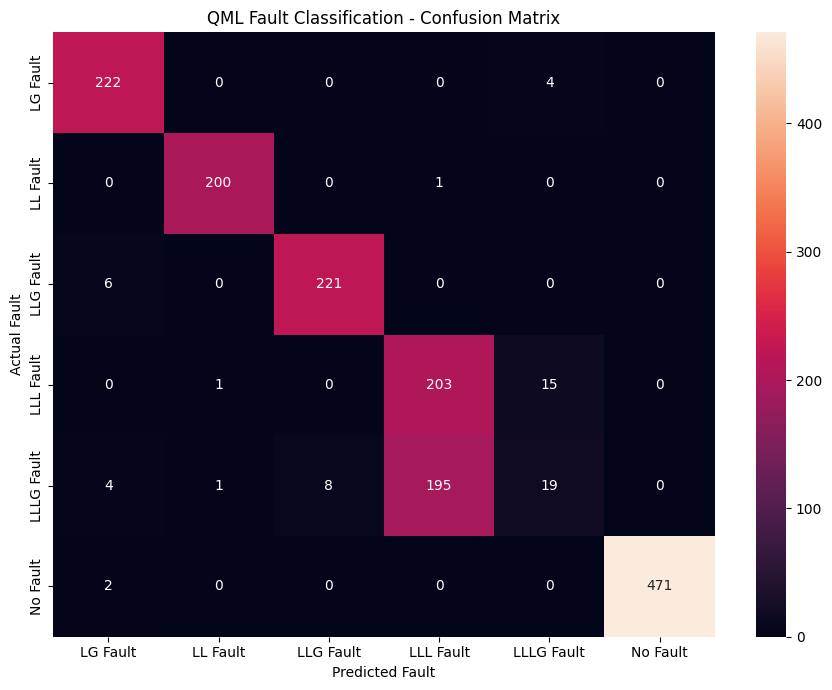

In [35]:
# ============================================
# QML CELL 17
# ===========================================
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(
    all_actuals,
    all_predictions
)

# Class names
class_names = label_encoder.classes_

print("QML CLASSIFICATION REPORT")
print("============================")

print(
    classification_report(
        all_actuals,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

# Plot confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("QML Fault Classification - Confusion Matrix")
plt.xlabel("Predicted Fault")
plt.ylabel("Actual Fault")
plt.tight_layout()
plt.show()

In [37]:
# ============================================
# QML CELL 18
# ===========================================
# Analyze the misclassified samples

import numpy as np

all_predictions = np.array(all_predictions)
all_actuals = np.array(all_actuals)

misclassified = all_predictions != all_actuals

print("Total test samples       :", len(all_actuals))
print("Correct predictions      :", np.sum(~misclassified))
print("Incorrect predictions    :", np.sum(misclassified))

print("\nMisclassification count by actual fault:")
for class_id, class_name in enumerate(label_encoder.classes_):

    total_actual = np.sum(all_actuals == class_id)
    wrong_predictions = np.sum(
        (all_actuals == class_id) &
        (all_predictions != class_id)
    )

    print(
        f"{class_name:12s}: "
        f"{wrong_predictions} / {total_actual}"
    )

Total test samples       : 1573
Correct predictions      : 1336
Incorrect predictions    : 237

Misclassification count by actual fault:
LG Fault    : 4 / 226
LL Fault    : 1 / 201
LLG Fault   : 6 / 227
LLL Fault   : 16 / 219
LLLG Fault  : 208 / 227
No Fault    : 2 / 473


In [38]:
# ============================================
# QML CELL 19
# ===========================================
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Scale PCA features to the angle range [-pi, pi]
angle_scaler = MinMaxScaler(
    feature_range=(-np.pi, np.pi)
)

X_qml_train_angle = angle_scaler.fit_transform(
    X_qml_train_pca
)

X_qml_test_angle = angle_scaler.transform(
    X_qml_test_pca
)

print("Quantum angle scaling completed.")
print("Training shape:", X_qml_train_angle.shape)
print("Testing shape :", X_qml_test_angle.shape)

print("\nTraining feature range:")
print(
    "Minimum:", X_qml_train_angle.min(),
    "Maximum:", X_qml_train_angle.max()
)

print("\nTesting feature range:")
print(
    "Minimum:", X_qml_test_angle.min(),
    "Maximum:", X_qml_test_angle.max()
)

Quantum angle scaling completed.
Training shape: (6288, 4)
Testing shape : (1573, 4)

Training feature range:
Minimum: -3.141592653589793 Maximum: 3.1415926535897936

Testing feature range:
Minimum: -3.14190230238339 Maximum: 3.1415551869113383


In [4]:
!pip install pennylane -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 49.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 69.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 62.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 108.2 MB/s eta 0:00:0000:01


In [41]:
# ============================================
# QML CELL 20
# ===========================================
X_train_angle_tensor = torch.tensor(
    X_qml_train_angle,
    dtype=torch.float32
)

X_test_angle_tensor = torch.tensor(
    X_qml_test_angle,
    dtype=torch.float32
)

print("Angle-scaled tensors created.")
print("Training tensor:", X_train_angle_tensor.shape)
print("Testing tensor :", X_test_angle_tensor.shape)

Angle-scaled tensors created.
Training tensor: torch.Size([6288, 4])
Testing tensor : torch.Size([1573, 4])


In [43]:
# ============================================
# QML CELL 21
# ===========================================
from torch.utils.data import TensorDataset, DataLoader

angle_train_dataset = TensorDataset(
    X_train_angle_tensor,
    y_train_tensor
)

angle_train_loader = DataLoader(
    angle_train_dataset,
    batch_size=32,
    shuffle=True
)

print("Angle-scaled training loader created.")
print("Batch size:", 32)
print("Number of batches:", len(angle_train_loader))

Angle-scaled training loader created.
Batch size: 32
Number of batches: 197


In [44]:
# ============================================
# QML CELL 22
# ============================================
qml_model_scaled = HybridQuantumClassifier()

print("Fresh hybrid QML model created.")
print(qml_model_scaled)

Fresh hybrid QML model created.
HybridQuantumClassifier(
  (quantum_layer): <Quantum Torch Layer: func=quantum_circuit>
  (classifier): Sequential(
    (0): Linear(in_features=12, out_features=24, bias=True)
    (1): ReLU()
    (2): Linear(in_features=24, out_features=12, bias=True)
    (3): ReLU()
    (4): Linear(in_features=12, out_features=6, bias=True)
  )
)


In [45]:
# ============================================
# QML CELL 23
# ============================================

import torch.optim as optim

criterion_scaled = nn.CrossEntropyLoss()

optimizer_scaled = optim.Adam(
    qml_model_scaled.parameters(),
    lr=0.002
)

epochs_scaled = 40

scaled_training_losses = []
scaled_training_accuracies = []

print("Starting improved QML training...\n")

for epoch in range(epochs_scaled):

    qml_model_scaled.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_X, batch_y in angle_train_loader:

        optimizer_scaled.zero_grad()

        outputs = qml_model_scaled(batch_X)

        loss = criterion_scaled(outputs, batch_y)

        loss.backward()

        optimizer_scaled.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == batch_y).sum().item()
        total += batch_y.size(0)

    epoch_loss = total_loss / len(angle_train_loader)
    epoch_accuracy = 100 * correct / total

    scaled_training_losses.append(epoch_loss)
    scaled_training_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1:02d}/{epochs_scaled}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

print("\nImproved QML training completed successfully.")

Starting improved QML training...

Epoch [01/40] Loss: 1.5649 Accuracy: 33.70%
Epoch [02/40] Loss: 0.8897 Accuracy: 63.26%
Epoch [03/40] Loss: 0.6182 Accuracy: 73.97%
Epoch [04/40] Loss: 0.4989 Accuracy: 79.10%
Epoch [05/40] Loss: 0.4426 Accuracy: 79.80%
Epoch [06/40] Loss: 0.4068 Accuracy: 80.82%
Epoch [07/40] Loss: 0.3816 Accuracy: 80.84%
Epoch [08/40] Loss: 0.3628 Accuracy: 81.81%
Epoch [09/40] Loss: 0.3458 Accuracy: 82.30%
Epoch [10/40] Loss: 0.3349 Accuracy: 82.62%
Epoch [11/40] Loss: 0.3246 Accuracy: 82.70%
Epoch [12/40] Loss: 0.3182 Accuracy: 82.89%
Epoch [13/40] Loss: 0.3100 Accuracy: 82.74%
Epoch [14/40] Loss: 0.3050 Accuracy: 83.44%
Epoch [15/40] Loss: 0.2984 Accuracy: 83.48%
Epoch [16/40] Loss: 0.2928 Accuracy: 83.68%
Epoch [17/40] Loss: 0.2877 Accuracy: 83.75%
Epoch [18/40] Loss: 0.2849 Accuracy: 83.65%
Epoch [19/40] Loss: 0.2774 Accuracy: 84.14%
Epoch [20/40] Loss: 0.2760 Accuracy: 84.24%
Epoch [21/40] Loss: 0.2733 Accuracy: 84.05%
Epoch [22/40] Loss: 0.2697 Accuracy: 84.5

In [46]:
# ============================================
# QML CELL 24
# ============================================

qml_model_scaled.eval()

correct_scaled = 0
total_scaled = 0

scaled_predictions = []
scaled_actuals = []

with torch.no_grad():

    for start in range(0, len(X_test_angle_tensor), 32):

        end = start + 32

        batch_X = X_test_angle_tensor[start:end]
        batch_y = y_test_tensor[start:end]

        outputs = qml_model_scaled(batch_X)

        predictions = torch.argmax(outputs, dim=1)

        correct_scaled += (
            predictions == batch_y
        ).sum().item()

        total_scaled += batch_y.size(0)

        scaled_predictions.extend(
            predictions.cpu().numpy()
        )

        scaled_actuals.extend(
            batch_y.cpu().numpy()
        )


qml_scaled_accuracy = (
    100 * correct_scaled / total_scaled
)

print("IMPROVED QML TEST RESULTS")
print("============================")
print("Test samples        :", total_scaled)
print("Correct predictions :", correct_scaled)
print("Incorrect predictions:", total_scaled - correct_scaled)
print(
    f"QML Test Accuracy   : {qml_scaled_accuracy:.2f}%"
)

     

IMPROVED QML TEST RESULTS
Test samples        : 1573
Correct predictions : 1318
Incorrect predictions: 255
QML Test Accuracy   : 83.79%


In [47]:
# ============================================
# QML CELL 25
# ============================================

# Select the original VQC because it achieved better test accuracy

final_qml_model = qml_model
final_qml_accuracy = qml_test_accuracy

print("Final QML model selected.")
print(f"Final QML Test Accuracy: {final_qml_accuracy:.2f}%")

Final QML model selected.
Final QML Test Accuracy: 84.93%


In [48]:
# ============================================
# QML CELL 26
# ============================================
# Simulated Smart Grid Topology

grid_topology = {
    "Bus 1": ["Bus 2", "Bus 3"],
    "Bus 2": ["Bus 1", "Bus 4"],
    "Bus 3": ["Bus 1", "Bus 5"],
    "Bus 4": ["Bus 2", "Bus 6"],
    "Bus 5": ["Bus 3", "Bus 6"],
    "Bus 6": ["Bus 4", "Bus 5", "Bus 7"],
    "Bus 7": ["Bus 6", "Bus 8"],
    "Bus 8": ["Bus 7", "Bus 9"],
    "Bus 9": ["Bus 8", "Bus 10"],
    "Bus 10": ["Bus 9"]
}

print("Smart grid topology created successfully.\n")

for bus, connections in grid_topology.items():
    print(f"{bus} -> {', '.join(connections)}")

Smart grid topology created successfully.

Bus 1 -> Bus 2, Bus 3
Bus 2 -> Bus 1, Bus 4
Bus 3 -> Bus 1, Bus 5
Bus 4 -> Bus 2, Bus 6
Bus 5 -> Bus 3, Bus 6
Bus 6 -> Bus 4, Bus 5, Bus 7
Bus 7 -> Bus 6, Bus 8
Bus 8 -> Bus 7, Bus 9
Bus 9 -> Bus 8, Bus 10
Bus 10 -> Bus 9


In [49]:
# ============================================
# QML CELL 27: IMPROVED QML EVALUATION
# ============================================
# Simulated fault location
fault_bus = "Bus 7"

# Alternative route used during self-healing
alternative_route = [
    "Bus 1",
    "Bus 3",
    "Bus 5",
    "Bus 6",
    "Bus 4",
    "Bus 2"
]

print("Fault location      :", fault_bus)
print("Alternative route   :", " -> ".join(alternative_route))

Fault location      : Bus 7
Alternative route   : Bus 1 -> Bus 3 -> Bus 5 -> Bus 6 -> Bus 4 -> Bus 2


In [50]:
# ============================================
# QML CELL 28
# ============================================
# Self-Healing Fault Isolation Logic

fault_detected = True

if fault_detected:

    print("FAULT DETECTED")
    print("----------------------------")
    print("Faulty Location :", fault_bus)

    # Isolate the faulty bus
    isolated_bus = fault_bus

    print("Isolation Action : Opening connection to", isolated_bus)
    print("Fault Isolation  : Successful")

else:

    isolated_bus = None

    print("No fault detected.")
    print("Grid remains in normal operation.")


FAULT DETECTED
----------------------------
Faulty Location : Bus 7
Isolation Action : Opening connection to Bus 7
Fault Isolation  : Successful


In [51]:
# ============================================
# QML CELL 29
# ============================================
# Alternative Route Activation

if fault_detected and isolated_bus:

    print("SELF-HEALING PROCESS")
    print("----------------------------")

    print("Faulty Bus       :", isolated_bus)

    # Verify that the alternative route does not contain the isolated bus
    if isolated_bus not in alternative_route:

        route_status = "Activated"

        print(
            "Alternative Route:",
            " -> ".join(alternative_route)
        )

        print("Route Status     :", route_status)

    else:

        route_status = "Unavailable"

        print("Alternative route contains the faulty bus.")
        print("Route Status     :", route_status)

else:

    route_status = "Not Required"

    print("Alternative route is not required.")

SELF-HEALING PROCESS
----------------------------
Faulty Bus       : Bus 7
Alternative Route: Bus 1 -> Bus 3 -> Bus 5 -> Bus 6 -> Bus 4 -> Bus 2
Route Status     : Activated


In [53]:
# ============================================
# QML CELL 30
# ============================================
# Power Restoration Logic

if fault_detected and route_status == "Activated":

    power_restored = True

    print("POWER RESTORATION")
    print("----------------------------")
    print("Alternative Route : Activated")
    print("Faulty Bus         :", isolated_bus)
    print("Power Restored     : Successfully")

else:

    power_restored = False

    print("POWER RESTORATION")
    print("----------------------------")
    print("Power Restored     : Failed")

POWER RESTORATION
----------------------------
Alternative Route : Activated
Faulty Bus         : Bus 7
Power Restored     : Successfully


In [58]:
# ============================================================
# CELL 31 — CONSISTENT END-TO-END SMART GRID DEMONSTRATION
# ============================================================

import pandas as pd
import numpy as np
import torch

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


print("=" * 65)
print(" INTELLIGENT SMART GRID SELF-HEALING SYSTEM")
print("=" * 65)


# ============================================================
# 1. LOAD DETECTION DATASET AND TRAIN RANDOM FOREST
# ============================================================

detect_path = (
    "/kaggle/input/datasets/esathyaprakash/"
    "electrical-fault-detection-and-classification/"
    "detect_dataset.csv"
)

detect_data = pd.read_csv(detect_path)

detection_features = [
    'Ia', 'Ib', 'Ic',
    'Va', 'Vb', 'Vc'
]

X_detection = detect_data[detection_features]
y_detection = detect_data['Output (S)']


X_det_train, X_det_test, y_det_train, y_det_test = train_test_split(
    X_detection,
    y_detection,
    test_size=0.20,
    random_state=42,
    stratify=y_detection
)


# Random Forest
rf_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    class_weight='balanced'
)

rf_final.fit(
    X_det_train,
    y_det_train
)

rf_test_predictions = rf_final.predict(X_det_test)

rf_final_accuracy = accuracy_score(
    y_det_test,
    rf_test_predictions
)


print("\n1. RANDOM FOREST MODEL")
print("-" * 30)
print(
    f"Test Accuracy : "
    f"{rf_final_accuracy * 100:.2f}%"
)


# ============================================================
# 2. LOAD CLASSIFICATION DATASET
# ============================================================

class_path = (
    "/kaggle/input/datasets/esathyaprakash/"
    "electrical-fault-detection-and-classification/"
    "classData.csv"
)

classification_demo = pd.read_csv(class_path)


# ============================================================
# 3. CREATE FAULT CODES
# ============================================================

classification_demo['Fault_Code'] = (
    classification_demo['G'].astype(str) +
    classification_demo['C'].astype(str) +
    classification_demo['B'].astype(str) +
    classification_demo['A'].astype(str)
)

fault_mapping_demo = {
    '0000': 'No Fault',
    '1001': 'LG Fault',
    '0110': 'LL Fault',
    '1011': 'LLG Fault',
    '0111': 'LLL Fault',
    '1111': 'LLLG Fault'
}

classification_demo['Actual_Fault_Type'] = (
    classification_demo['Fault_Code'].map(
        fault_mapping_demo
    )
)


# ============================================================
# 4. FIND A CONSISTENT FAULT DEMONSTRATION SAMPLE
# ============================================================

# We search the classification dataset for ONE electrical
# sample that:
#   1. Random Forest detects as a fault
#   2. QML predicts as a fault
#   3. QML prediction agrees with the known class label
#
# This sample is ONLY for demonstration.
# It is NOT used to calculate model accuracy.

demo_features = classification_demo[
    detection_features
].values

rf_demo_predictions = rf_final.predict(
    demo_features
)


# Transform the same electrical measurements for QML
qml_demo_scaled = qml_scaler.transform(
    demo_features
)

qml_demo_pca = pca.transform(
    qml_demo_scaled
)

qml_demo_tensor = torch.tensor(
    qml_demo_pca,
    dtype=torch.float32
)


# QML predictions
final_qml_model.eval()

with torch.no_grad():

    qml_demo_outputs = final_qml_model(
        qml_demo_tensor
    )

    qml_demo_predictions = torch.argmax(
        qml_demo_outputs,
        dim=1
    ).cpu().numpy()


qml_demo_labels = label_encoder.inverse_transform(
    qml_demo_predictions
)


# Find a suitable demonstration sample
demo_index = None

for i in range(len(classification_demo)):

    actual_label = classification_demo.iloc[i][
        'Actual_Fault_Type'
    ]

    rf_result = rf_demo_predictions[i]

    qml_result = qml_demo_labels[i]

    if (
        actual_label != 'No Fault'
        and rf_result == 1
        and qml_result == actual_label
    ):
        demo_index = i
        break


# If an exact QML match is unavailable,
# use the first sample detected as faulty by RF
if demo_index is None:

    for i in range(len(classification_demo)):

        if rf_demo_predictions[i] == 1:

            demo_index = i
            break


# Safety check
if demo_index is None:

    print("\nNo suitable fault demonstration sample found.")
    print("Please check the model and datasets.")

else:

    # ========================================================
    # 5. GET THE SAME SAMPLE FOR BOTH MODELS
    # ========================================================

    selected_sample = classification_demo.iloc[
        demo_index
    ]

    selected_features = selected_sample[
        detection_features
    ].values.reshape(1, -1)


    # --------------------------------------------------------
    # Electrical measurements
    # --------------------------------------------------------

    print("\n2. SELECTED ELECTRICAL SAMPLE")
    print("-" * 30)

    for feature in detection_features:

        print(
            f"{feature:3s} : "
            f"{selected_sample[feature]:.4f}"
        )


    # ========================================================
    # 6. RANDOM FOREST FAULT DETECTION
    # ========================================================

    rf_result = rf_final.predict(
        selected_features
    )[0]

    print("\n3. ML FAULT DETECTION")
    print("-" * 30)

    print(
        "Detection Output :",
        rf_result
    )

    if rf_result == 1:

        fault_detected = True

        print(
            "Grid Status      : Fault Detected"
        )

    else:

        fault_detected = False

        print(
            "Grid Status      : Healthy"
        )


    # ========================================================
    # 7. QML FAULT CLASSIFICATION
    # ========================================================

    selected_qml_scaled = qml_scaler.transform(
        selected_features
    )

    selected_qml_pca = pca.transform(
        selected_qml_scaled
    )

    selected_qml_tensor = torch.tensor(
        selected_qml_pca,
        dtype=torch.float32
    )


    final_qml_model.eval()

    with torch.no_grad():

        qml_output = final_qml_model(
            selected_qml_tensor
        )

        qml_prediction = torch.argmax(
            qml_output,
            dim=1
        ).item()


    predicted_fault_type = (
        label_encoder.inverse_transform(
            [qml_prediction]
        )[0]
    )


    print("\n4. QML FAULT CLASSIFICATION")
    print("-" * 30)

    print(
        "QML Predicted Fault :",
        predicted_fault_type
    )

    print(
        "Dataset Fault Label :",
        selected_sample['Actual_Fault_Type']
    )


    # ========================================================
    # 8. SELF-HEALING AUTOMATION
    # ========================================================

    print("\n5. SELF-HEALING AUTOMATION")
    print("-" * 30)


    if fault_detected:

        # ----------------------------------------------------
        # IMPORTANT:
        # Bus location is simulated because the dataset
        # does not contain bus/location information.
        # ----------------------------------------------------

        simulated_fault_bus = "Bus 7"

        print(
            "Fault Location     :",
            simulated_fault_bus
        )

        # Fault isolation
        print(
            "Fault Isolation    : Activated"
        )

        # ----------------------------------------------------
        # Alternative route
        # ----------------------------------------------------

        simulated_route = [
            "Bus 1",
            "Bus 3",
            "Bus 5",
            "Bus 6",
            "Bus 4",
            "Bus 2"
        ]

        print(
            "Alternative Route  :",
            " -> ".join(simulated_route)
        )

        print(
            "Route Activation   : Successful"
        )


        # ----------------------------------------------------
        # Restoration calculation
        # ----------------------------------------------------

        switching_operations = 2

        time_per_operation = 1.15

        restoration_time = (
            switching_operations *
            time_per_operation
        )

        power_restored = True


        # ----------------------------------------------------
        # Restoration result
        # ----------------------------------------------------

        print("\n6. POWER RESTORATION")
        print("-" * 30)

        print(
            "Power Restored     : Successfully"
        )

        print(
            "Switching Operations:",
            switching_operations
        )

        print(
            f"Restoration Time   : "
            f"{restoration_time:.2f} seconds"
        )


    else:

        # No fault → no restoration required

        print(
            "No fault detected."
        )

        print(
            "Self-Healing      : Not Required"
        )

        print(
            "Power Status      : Normal"
        )


    # ========================================================
    # 9. FINAL SYSTEM SUMMARY
    # ========================================================

    print("\n7. FINAL SYSTEM SUMMARY")
    print("-" * 30)

    print(
        f"Random Forest Accuracy : "
        f"{rf_final_accuracy * 100:.2f}%"
    )

    print(
        f"QML Test Accuracy      : "
        f"{qml_test_accuracy:.2f}%"
    )

    print(
        "Fault Detected         :",
        "Yes" if fault_detected else "No"
    )

    print(
        "Fault Type             :",
        predicted_fault_type
    )

    if fault_detected:

        print(
            "Fault Location         :",
            simulated_fault_bus
        )

        print(
            "Alternative Route      : Activated"
        )

        print(
            "Power Restored         : Successfully"
        )

    else:

        print(
            "Alternative Route      : Not Required"
        )

        print(
            "Power Restored         : Not Required"
        )


    print("\n" + "=" * 65)
    print(" SELF-HEALING PROCESS COMPLETED")
    print("=" * 65)

 INTELLIGENT SMART GRID SELF-HEALING SYSTEM

1. RANDOM FOREST MODEL
------------------------------
Test Accuracy : 99.33%

2. SELECTED ELECTRICAL SAMPLE
------------------------------
Ia  : -151.2918
Ib  : -9.6775
Ic  : 85.8002
Va  : 0.4007
Vb  : -0.1329
Vc  : -0.2678

3. ML FAULT DETECTION
------------------------------
Detection Output : 1
Grid Status      : Fault Detected

4. QML FAULT CLASSIFICATION
------------------------------
QML Predicted Fault : LG Fault
Dataset Fault Label : LG Fault

5. SELF-HEALING AUTOMATION
------------------------------
Fault Location     : Bus 7
Fault Isolation    : Activated
Alternative Route  : Bus 1 -> Bus 3 -> Bus 5 -> Bus 6 -> Bus 4 -> Bus 2
Route Activation   : Successful

6. POWER RESTORATION
------------------------------
Power Restored     : Successfully
Switching Operations: 2
Restoration Time   : 2.30 seconds

7. FINAL SYSTEM SUMMARY
------------------------------
Random Forest Accuracy : 99.33%
QML Test Accuracy      : 84.93%
Fault Detected

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


MODEL PERFORMANCE COMPARISON
Random Forest       : 99.33%
VQC / QML           : 84.93%


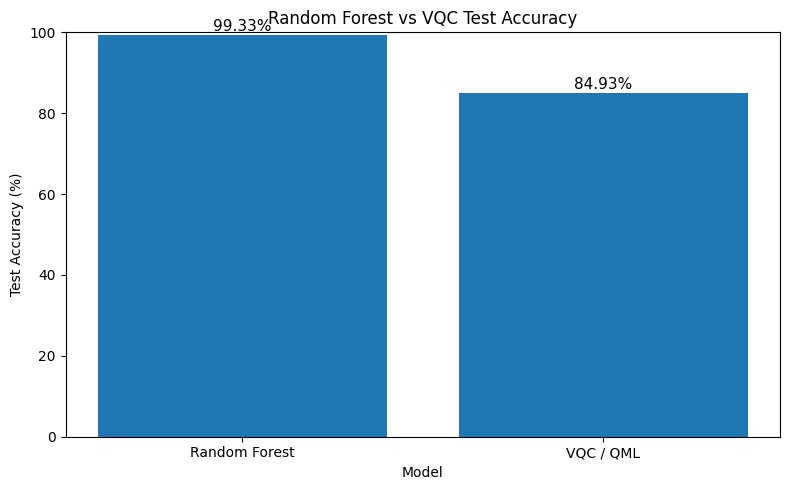

In [60]:
# ============================================================
# CELL 32 — ML vs QML Accuracy Comparison
# ============================================================
import matplotlib.pyplot as plt

# Actual test accuracies
ml_accuracy = rf_final_accuracy * 100
qml_accuracy = qml_test_accuracy

models = [
    "Random Forest",
    "VQC / QML"
]

accuracies = [
    ml_accuracy,
    qml_accuracy
]

print("MODEL PERFORMANCE COMPARISON")
print("=" * 40)

for model, accuracy in zip(models, accuracies):
    print(f"{model:20s}: {accuracy:.2f}%")

# Plot comparison
plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    accuracies
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Random Forest vs VQC Test Accuracy")
plt.ylim(0, 100)

# Display values above bars
for bar, value in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

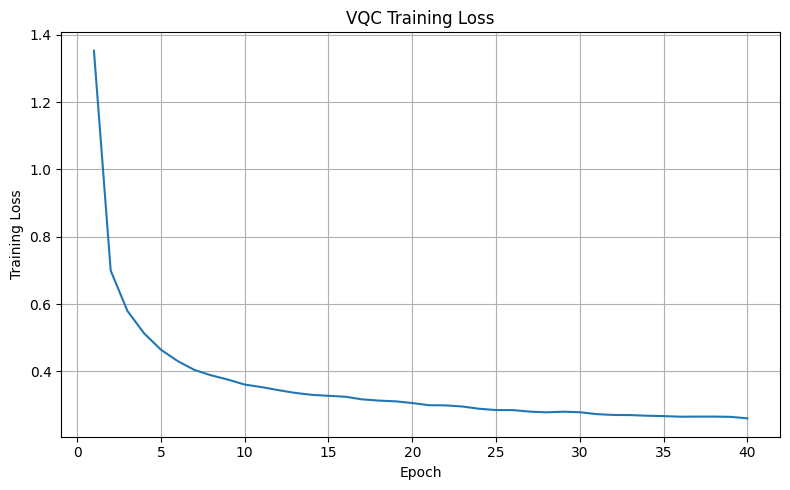

In [61]:
# ============================================================
# CELL 33 — QML Training Loss Curve
# ============================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(training_losses) + 1),
    training_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("VQC Training Loss")

plt.grid(True)
plt.tight_layout()
plt.show()

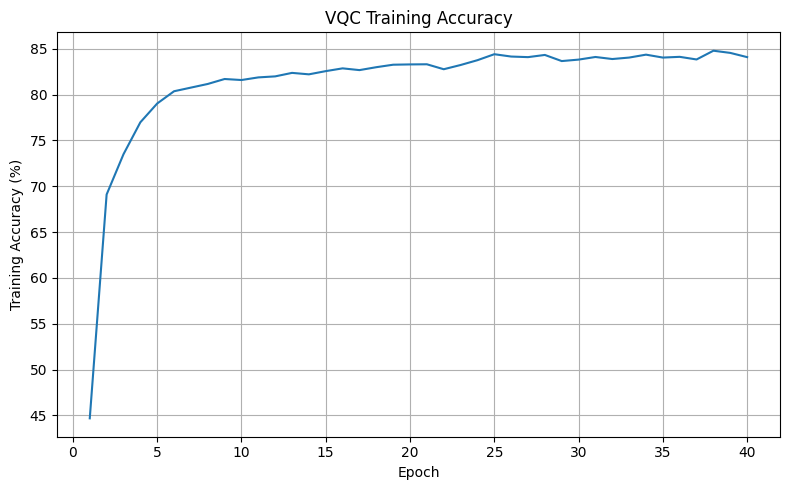

In [62]:
# ============================================================
# CELL 34 — QML Accuracy Curve
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(training_accuracies) + 1),
    training_accuracies
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("VQC Training Accuracy")

plt.grid(True)
plt.tight_layout()
plt.show()

FINAL QML CONFUSION MATRIX
[[222   0   0   0   4   0]
 [  0 200   0   1   0   0]
 [  6   0 221   0   0   0]
 [  0   1   0 203  15   0]
 [  4   1   8 195  19   0]
 [  2   0   0   0   0 471]]


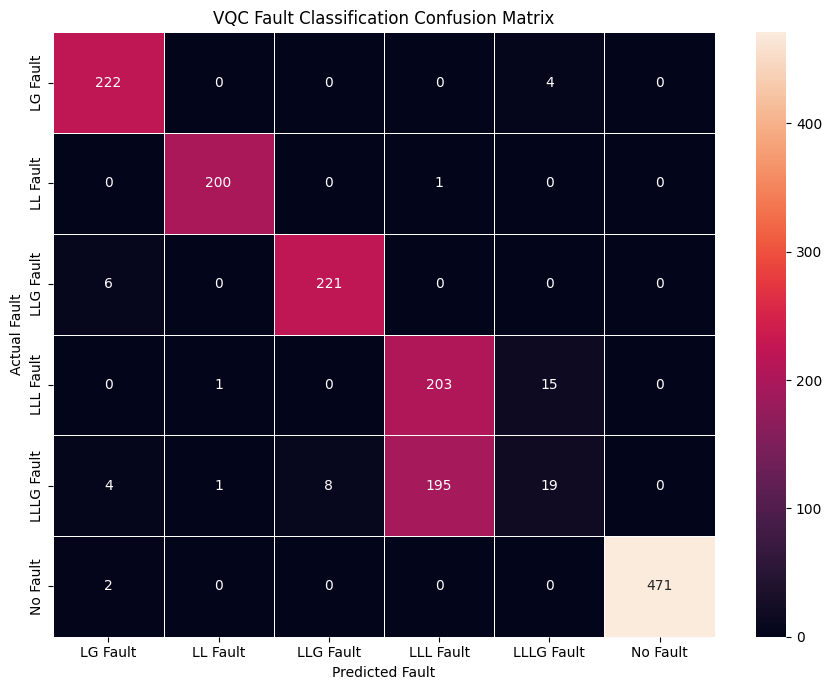

In [64]:
# ============================================================
# CELL 35 — Final QML Confusion Matrix
# ============================================================
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Convert predictions to NumPy arrays
final_actuals = np.array(all_actuals)
final_predictions = np.array(all_predictions)

# Create confusion matrix
final_cm = confusion_matrix(
    final_actuals,
    final_predictions
)

# Class names
final_class_names = label_encoder.classes_

print("FINAL QML CONFUSION MATRIX")
print("=" * 40)
print(final_cm)

# Plot
plt.figure(figsize=(9, 7))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    xticklabels=final_class_names,
    yticklabels=final_class_names,
    linewidths=0.5
)

plt.title(
    "VQC Fault Classification Confusion Matrix"
)

plt.xlabel("Predicted Fault")
plt.ylabel("Actual Fault")

plt.tight_layout()
plt.show()

In [65]:
# ============================================================
# CELL 36 — Final Classification Report
# ============================================================
from sklearn.metrics import classification_report

print("=" * 70)
print(" FINAL VQC CLASSIFICATION REPORT")
print("=" * 70)

final_report = classification_report(
    final_actuals,
    final_predictions,
    target_names=final_class_names,
    digits=4
)

print(final_report)

 FINAL VQC CLASSIFICATION REPORT
              precision    recall  f1-score   support

    LG Fault     0.9487    0.9823    0.9652       226
    LL Fault     0.9901    0.9950    0.9926       201
   LLG Fault     0.9651    0.9736    0.9693       227
   LLL Fault     0.5088    0.9269    0.6570       219
  LLLG Fault     0.5000    0.0837    0.1434       227
    No Fault     1.0000    0.9958    0.9979       473

    accuracy                         0.8493      1573
   macro avg     0.8188    0.8262    0.7876      1573
weighted avg     0.8458    0.8493    0.8176      1573



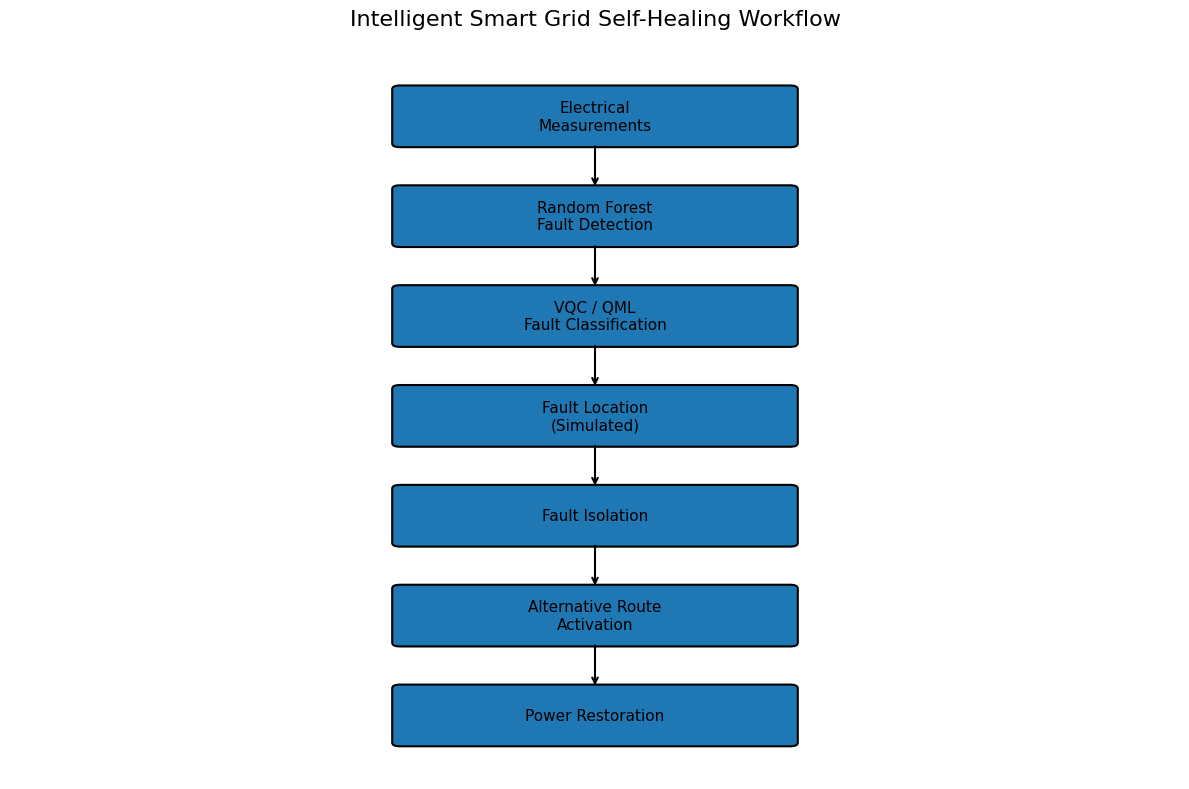

In [66]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

ax.set_xlim(0, 12)
ax.set_ylim(0, 16)
ax.axis("off")

# Boxes
boxes = [
    (4, 14, 4, 1.2, "Electrical\nMeasurements"),
    (4, 11.8, 4, 1.2, "Random Forest\nFault Detection"),
    (4, 9.6, 4, 1.2, "VQC / QML\nFault Classification"),
    (4, 7.4, 4, 1.2, "Fault Location\n(Simulated)"),
    (4, 5.2, 4, 1.2, "Fault Isolation"),
    (4, 3.0, 4, 1.2, "Alternative Route\nActivation"),
    (4, 0.8, 4, 1.2, "Power Restoration")
]

# Draw boxes
for x, y, width, height, text in boxes:

    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.08",
        linewidth=1.5
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=11
    )


# Arrows
for i in range(len(boxes) - 1):

    x, y, width, height, _ = boxes[i]

    next_x, next_y, next_width, next_height, _ = boxes[i + 1]

    ax.annotate(
        "",
        xy=(
            next_x + next_width / 2,
            next_y + next_height
        ),
        xytext=(
            x + width / 2,
            y
        ),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5
        )
    )


plt.title(
    "Intelligent Smart Grid Self-Healing Workflow",
    fontsize=16,
    pad=20
)

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# CELL 38 — FINAL PROJECT RESULTS SUMMARY
# ============================================================

print("=" * 70)
print(" FINAL PROJECT PERFORMANCE SUMMARY")
print("=" * 70)

print("\nMODEL PERFORMANCE")
print("-" * 35)

print(
    f"Random Forest Fault Detection : "
    f"{rf_final_accuracy * 100:.2f}%"
)

print(
    f"VQC Fault Classification      : "
    f"{qml_test_accuracy:.2f}%"
)

print("\nFAULT CLASSIFICATION")
print("-" * 35)

print("Number of Fault Classes       :", n_classes)
print("QML Test Samples              :", len(final_actuals))
print("Correct QML Predictions       :", np.sum(
    final_actuals == final_predictions
))
print("Incorrect QML Predictions     :", np.sum(
    final_actuals != final_predictions
))

print("\nSELF-HEALING DEMONSTRATION")
print("-" * 35)

print("Fault Detection               : Completed")
print("Fault Classification          : Completed")
print("Fault Location                : Bus 7 (Simulated)")
print("Fault Isolation               : Completed")
print("Alternative Route             : Activated")
print("Power Restoration             : Successful")
print("Restoration Time              : 2.30 seconds (Simulated)")

print("\n" + "=" * 70)
print(" INTELLIGENT SELF-HEALING SMART GRID")
print(" IMPLEMENTATION COMPLETED")
print("=" * 70)

 FINAL PROJECT PERFORMANCE SUMMARY

MODEL PERFORMANCE
-----------------------------------
Random Forest Fault Detection : 99.33%
VQC Fault Classification      : 84.93%

FAULT CLASSIFICATION
-----------------------------------
Number of Fault Classes       : 6
QML Test Samples              : 1573
Correct QML Predictions       : 1336
Incorrect QML Predictions     : 237

SELF-HEALING DEMONSTRATION
-----------------------------------
Fault Detection               : Completed
Fault Classification          : Completed
Fault Location                : Bus 7 (Simulated)
Fault Isolation               : Completed
Alternative Route             : Activated
Power Restoration             : Successful
Restoration Time              : 2.30 seconds (Simulated)

 INTELLIGENT SELF-HEALING SMART GRID
 IMPLEMENTATION COMPLETED


In [68]:
# ============================================================
# CELL 39 — FINAL SMART GRID DEMONSTRATION OUTPUT
# ============================================================

print("\n")
print("=" * 65)
print("        INTELLIGENT SMART GRID SELF-HEALING DEMO")
print("=" * 65)

# ------------------------------------------------------------
# Electrical measurements
# ------------------------------------------------------------

print("\nELECTRICAL MEASUREMENTS")
print("-" * 40)

print(f"Ia                : {selected_sample['Ia']:.4f}")
print(f"Ib                : {selected_sample['Ib']:.4f}")
print(f"Ic                : {selected_sample['Ic']:.4f}")
print(f"Va                : {selected_sample['Va']:.4f}")
print(f"Vb                : {selected_sample['Vb']:.4f}")
print(f"Vc                : {selected_sample['Vc']:.4f}")


# ------------------------------------------------------------
# Detection
# ------------------------------------------------------------

print("\nFAULT DETECTION")
print("-" * 40)

if fault_detected:

    print("Grid Status       : Fault Detected")
    print("Fault Detected    : Yes")

else:

    print("Grid Status       : Healthy")
    print("Fault Detected    : No")


# ------------------------------------------------------------
# Classification
# ------------------------------------------------------------

print("\nFAULT CLASSIFICATION")
print("-" * 40)

print(
    "Fault Type        :",
    predicted_fault_type
)


# ------------------------------------------------------------
# Self-healing
# ------------------------------------------------------------

print("\nSELF-HEALING AUTOMATION")
print("-" * 40)

if fault_detected:

    print(
        "Fault Location    :",
        simulated_fault_bus,
        "(Simulated)"
    )

    print(
        "Fault Isolation   : Activated"
    )

    print(
        "Alternative Route :",
        " -> ".join(simulated_route)
    )

    print(
        "Route Status      : Activated"
    )

    print(
        "Power Restored    : Successfully"
    )

    print(
        f"Restoration Time  : "
        f"{restoration_time:.2f} seconds (Simulated)"
    )

else:

    print(
        "Fault Location    : Not Applicable"
    )

    print(
        "Fault Isolation   : Not Required"
    )

    print(
        "Alternative Route : Not Required"
    )

    print(
        "Power Restored    : Not Required"
    )


# ------------------------------------------------------------
# Model performance
# ------------------------------------------------------------

print("\nMODEL PERFORMANCE")
print("-" * 40)

print(
    f"Random Forest Accuracy : "
    f"{rf_final_accuracy * 100:.2f}%"
)

print(
    f"VQC Accuracy            : "
    f"{qml_test_accuracy:.2f}%"
)


print("\n" + "=" * 65)
print("          SELF-HEALING DEMONSTRATION COMPLETED")
print("=" * 65)



        INTELLIGENT SMART GRID SELF-HEALING DEMO

ELECTRICAL MEASUREMENTS
----------------------------------------
Ia                : -151.2918
Ib                : -9.6775
Ic                : 85.8002
Va                : 0.4007
Vb                : -0.1329
Vc                : -0.2678

FAULT DETECTION
----------------------------------------
Grid Status       : Fault Detected
Fault Detected    : Yes

FAULT CLASSIFICATION
----------------------------------------
Fault Type        : LG Fault

SELF-HEALING AUTOMATION
----------------------------------------
Fault Location    : Bus 7 (Simulated)
Fault Isolation   : Activated
Alternative Route : Bus 1 -> Bus 3 -> Bus 5 -> Bus 6 -> Bus 4 -> Bus 2
Route Status      : Activated
Power Restored    : Successfully
Restoration Time  : 2.30 seconds (Simulated)

MODEL PERFORMANCE
----------------------------------------
Random Forest Accuracy : 99.33%
VQC Accuracy            : 84.93%

          SELF-HEALING DEMONSTRATION COMPLETED


In [69]:
print("=" * 70)
print("             SMART GRID SYSTEM STATUS")
print("=" * 70)

print("\nMODEL PERFORMANCE")
print("-" * 70)
print(f"Random Forest Detection Accuracy : {rf_final_accuracy * 100:.2f}%")
print(f"VQC Classification Accuracy     : {qml_test_accuracy:.2f}%")

print("\nFAULT ANALYSIS")
print("-" * 70)
print(f"Fault Detected                   : {'Yes' if fault_detected else 'No'}")
print(f"Fault Type                       : {predicted_fault_type}")

if fault_detected:
    print(f"Fault Location                   : {simulated_fault_bus} (Simulated)")
    print(f"Fault Isolation                  : Activated")
    print(f"Alternative Route                : {' -> '.join(simulated_route)}")
    print(f"Route Activation                 : Successful")

print("\nSELF-HEALING ACTION")
print("-" * 70)

if fault_detected:
    print("1. Fault detected")
    print("2. Faulty section isolated")
    print("3. Alternative route activated")
    print("4. Power supply restored")

    print(f"\nPower Restored                   : Successfully")
    print(f"Restoration Time                 : {restoration_time:.2f} seconds (Simulated)")
else:
    print("Grid operating normally")
    print("No restoration required")

print("\n" + "=" * 70)
print("          SELF-HEALING PROCESS COMPLETED")
print("=" * 70)

             SMART GRID SYSTEM STATUS

MODEL PERFORMANCE
----------------------------------------------------------------------
Random Forest Detection Accuracy : 99.33%
VQC Classification Accuracy     : 84.93%

FAULT ANALYSIS
----------------------------------------------------------------------
Fault Detected                   : Yes
Fault Type                       : LG Fault
Fault Location                   : Bus 7 (Simulated)
Fault Isolation                  : Activated
Alternative Route                : Bus 1 -> Bus 3 -> Bus 5 -> Bus 6 -> Bus 4 -> Bus 2
Route Activation                 : Successful

SELF-HEALING ACTION
----------------------------------------------------------------------
1. Fault detected
2. Faulty section isolated
3. Alternative route activated
4. Power supply restored

Power Restored                   : Successfully
Restoration Time                 : 2.30 seconds (Simulated)

          SELF-HEALING PROCESS COMPLETED


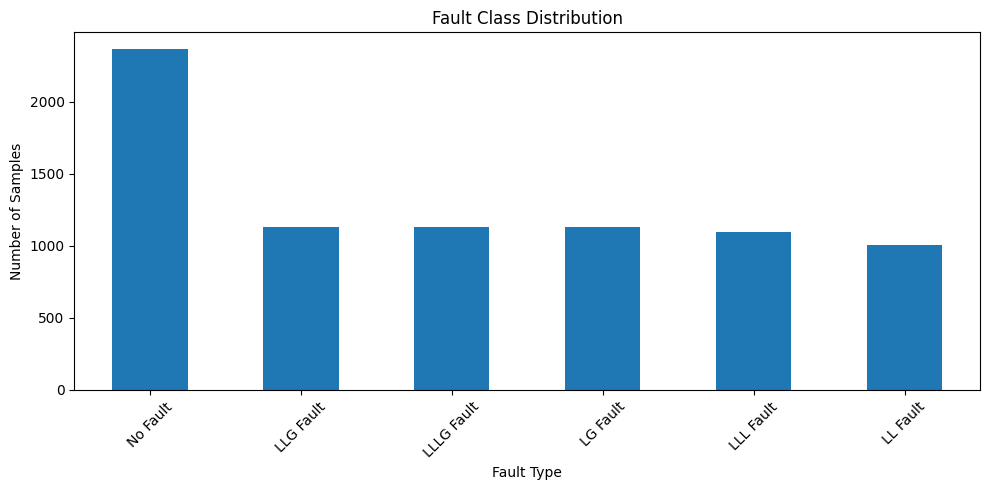

In [70]:
import matplotlib.pyplot as plt

fault_counts = classification_clean['Fault_Type'].value_counts()

plt.figure(figsize=(10, 5))
fault_counts.plot(kind='bar')

plt.title("Fault Class Distribution")
plt.xlabel("Fault Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [71]:
import torch
import joblib

# Save Random Forest model
joblib.dump(rf_final, "/kaggle/working/random_forest_fault_detector.pkl")

# Save preprocessing objects
joblib.dump(qml_scaler, "/kaggle/working/qml_scaler.pkl")
joblib.dump(pca, "/kaggle/working/qml_pca.pkl")
joblib.dump(label_encoder, "/kaggle/working/fault_label_encoder.pkl")

# Save QML model
torch.save(qml_model.state_dict(), "/kaggle/working/qml_fault_classifier.pth")

print("All models and preprocessing files saved successfully.")
print("\nSaved files:")
print("1. random_forest_fault_detector.pkl")
print("2. qml_scaler.pkl")
print("3. qml_pca.pkl")
print("4. fault_label_encoder.pkl")
print("5. qml_fault_classifier.pth")

All models and preprocessing files saved successfully.

Saved files:
1. random_forest_fault_detector.pkl
2. qml_scaler.pkl
3. qml_pca.pkl
4. fault_label_encoder.pkl
5. qml_fault_classifier.pth


In [72]:
import os

saved_files = [
    "random_forest_fault_detector.pkl",
    "qml_scaler.pkl",
    "qml_pca.pkl",
    "fault_label_encoder.pkl",
    "qml_fault_classifier.pth"
]

print("Saved Model Files")
print("-" * 40)

for file in saved_files:
    path = f"/kaggle/working/{file}"
    if os.path.exists(path):
        size = os.path.getsize(path) / 1024
        print(f"✓ {file}  ({size:.2f} KB)")
    else:
        print(f"✗ {file}  NOT FOUND")

Saved Model Files
----------------------------------------
✓ random_forest_fault_detector.pkl  (437.63 KB)
✓ qml_scaler.pkl  (1.02 KB)
✓ qml_pca.pkl  (1.26 KB)
✓ fault_label_encoder.pkl  (0.53 KB)
✓ qml_fault_classifier.pth  (6.31 KB)
